# HW2 — Uniform Convergence and the Limits of Learning
**Statistical and Machine Learning — M2, Université de Haute-Alsace**

Goal: study uniform convergence (Session 3) and the No-Free-Lunch principle and inductive bias (Sessions 1 and 4) with Monte-Carlo simulations, using NumPy only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)  # fixed seed for reproducibility

## 0. Experimental parameters

The two theoretical quantities used in Part I are the Hoeffding bound $2e^{-2m\varepsilon^2}$ and the finite-class sample complexity
$$m \ge \frac{\log(2|H|/\delta)}{2\varepsilon^2}.$$
We use them to choose the parameters.

In [2]:
EPSILON = 0.05
DELTA = 0.05
M_VALUES = [10, 25, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000]   # sample sizes (Part I)
H_SIZES = [5, 10, 50, 100, 500]                                             # class sizes |H|
N_REP = 5000                 # Monte-Carlo repetitions (Part I)

N_DOMAIN = 100               # domain size N (Parts II and III)
M_TASKS = [5, 10, 20, 50, 100, 200, 500]   # sample sizes (Parts II and III)
N_REP_TASKS = 2000           # random tasks per value of m

print("Hoeffding bound < 1 from m =", int(np.ceil(np.log(2) / (2 * EPSILON**2))))
for K in H_SIZES:
    print(f"|H| = {K:3d}: theoretical sample size = {np.log(2 * K / DELTA) / (2 * EPSILON**2):.0f}")

Hoeffding bound < 1 from m = 139
|H| =   5: theoretical sample size = 1060
|H| =  10: theoretical sample size = 1198
|H| =  50: theoretical sample size = 1520
|H| = 100: theoretical sample size = 1659
|H| = 500: theoretical sample size = 1981


- **ε = δ = 0.05**: the Hoeffding bound is useless (≥ 1) until m = 139, and the theoretical sample size goes from about 1060 to 1980 depending on |H|. A grid of m from 10 to 3000 covers both regimes.
- **|H| ∈ {5, 10, 50, 100, 500}**: as suggested, a factor 100 between the smallest and largest class.
- **5000 repetitions** in Part I: the standard deviation of an estimated probability is at most $0.5/\sqrt{5000} \approx 0.007$.
- **N = 100** in Parts II and III, with m from 5 to 500: this covers m < N/2 (the No-Free-Lunch regime) up to m much larger than N. 2000 random tasks per m are enough for smooth curves.

# Part I – Simulating Uniform Convergence

Each hypothesis has a true risk $L_\mathcal{D}(h_j) = p_j$ and makes $E_j \sim \text{Binomial}(m, p_j)$ errors on the training sample, so $L_S(h_j) = E_j/m$. As in the statement, the $E_j$ are simulated independently.

## 1. Empirical Risk as a Random Variable

$L_S(h)$ is an average of m errors, so
$$\mathbb{E}[L_S(h)] = L_\mathcal{D}(h) = p, \qquad \text{std}(L_S(h)) = \sqrt{\frac{p(1-p)}{m}}.$$

p = 0.1 | m =   10 | mean of L_S = 0.0998 | std = 0.0947 | sqrt(p(1-p)/m) = 0.0949
p = 0.1 | m =   50 | mean of L_S = 0.1002 | std = 0.0425 | sqrt(p(1-p)/m) = 0.0424
p = 0.1 | m =  200 | mean of L_S = 0.1004 | std = 0.0214 | sqrt(p(1-p)/m) = 0.0212
p = 0.1 | m = 1000 | mean of L_S = 0.1002 | std = 0.0095 | sqrt(p(1-p)/m) = 0.0095
p = 0.3 | m =   10 | mean of L_S = 0.2991 | std = 0.1457 | sqrt(p(1-p)/m) = 0.1449
p = 0.3 | m =   50 | mean of L_S = 0.3007 | std = 0.0652 | sqrt(p(1-p)/m) = 0.0648
p = 0.3 | m =  200 | mean of L_S = 0.3000 | std = 0.0318 | sqrt(p(1-p)/m) = 0.0324
p = 0.3 | m = 1000 | mean of L_S = 0.3002 | std = 0.0145 | sqrt(p(1-p)/m) = 0.0145
p = 0.5 | m =   10 | mean of L_S = 0.4982 | std = 0.1548 | sqrt(p(1-p)/m) = 0.1581
p = 0.5 | m =   50 | mean of L_S = 0.5019 | std = 0.0696 | sqrt(p(1-p)/m) = 0.0707
p = 0.5 | m =  200 | mean of L_S = 0.5001 | std = 0.0359 | sqrt(p(1-p)/m) = 0.0354
p = 0.5 | m = 1000 | mean of L_S = 0.4998 | std = 0.0157 | sqrt(p(1-p)/m) = 0.0158


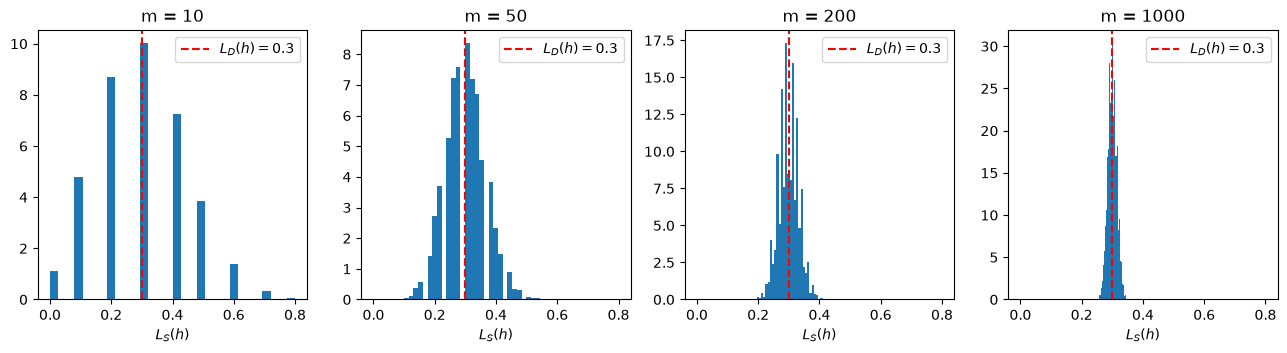

In [3]:
p_values = [0.1, 0.3, 0.5]       # true risks L_D(h) of three hypotheses
m_list = [10, 50, 200, 1000]

for p in p_values:
    for m in m_list:
        L_S = rng.binomial(m, p, size=N_REP) / m
        print(f"p = {p} | m = {m:4d} | mean of L_S = {L_S.mean():.4f} | std = {L_S.std():.4f} | sqrt(p(1-p)/m) = {np.sqrt(p * (1 - p) / m):.4f}")

p = 0.3                           # hypothesis used for the histograms and for Task 2
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
for ax, m in zip(axes, m_list):
    L_S = rng.binomial(m, p, size=N_REP) / m
    ax.hist(L_S, bins=30, density=True)
    ax.axvline(p, color="red", linestyle="--", label="$L_D(h) = 0.3$")
    ax.set_title(f"m = {m}")
    ax.set_xlabel("$L_S(h)$")
    ax.legend()
plt.show()

For the three hypotheses, the mean of $L_S$ is equal to $L_\mathcal{D}(h) = p$ up to 0.002: the empirical risk is an unbiased estimate of the true risk. Its spread shrinks with m and matches $\sqrt{p(1-p)/m}$ (for p = 0.3: 0.146 for m = 10, 0.015 for m = 1000), so multiplying m by 100 divides the standard deviation by 10. The spread is largest for p = 0.5 and smallest for p = 0.1, since $p(1-p)$ is maximal at 0.5. The histograms (p = 0.3) also show that $L_S$ becomes concentrated and close to a Gaussian for large m.

## 2. Deviation Between Empirical and True Risk

Hoeffding's inequality (Session 3) gives, for one fixed hypothesis,
$$\Pr\big[|L_S(h) - L_\mathcal{D}(h)| > \varepsilon\big] \le 2e^{-2m\varepsilon^2}.$$

m =   10 | Pr(|L_S - L_D| > eps) = 0.7390 | Hoeffding = 1.0000
m =   25 | Pr(|L_S - L_D| > eps) = 0.6562 | Hoeffding = 1.0000
m =   50 | Pr(|L_S - L_D| > eps) = 0.4218 | Hoeffding = 1.0000
m =  100 | Pr(|L_S - L_D| > eps) = 0.2142 | Hoeffding = 1.0000
m =  200 | Pr(|L_S - L_D| > eps) = 0.1004 | Hoeffding = 0.7358
m =  300 | Pr(|L_S - L_D| > eps) = 0.0454 | Hoeffding = 0.4463
m =  500 | Pr(|L_S - L_D| > eps) = 0.0146 | Hoeffding = 0.1642
m =  750 | Pr(|L_S - L_D| > eps) = 0.0022 | Hoeffding = 0.0470
m = 1000 | Pr(|L_S - L_D| > eps) = 0.0004 | Hoeffding = 0.0135
m = 1500 | Pr(|L_S - L_D| > eps) = 0.0000 | Hoeffding = 0.0011
m = 2000 | Pr(|L_S - L_D| > eps) = 0.0000 | Hoeffding = 0.0001
m = 3000 | Pr(|L_S - L_D| > eps) = 0.0000 | Hoeffding = 0.0000


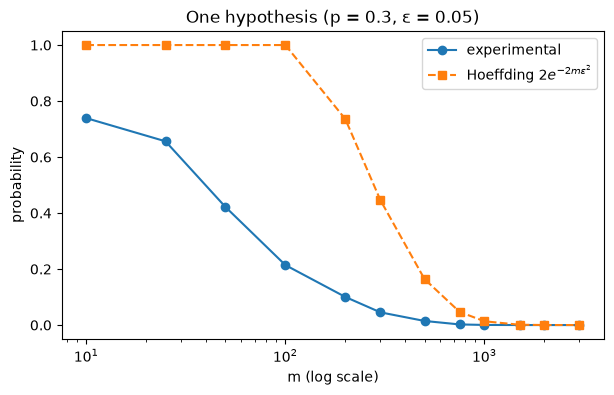

In [4]:
p_single = []
for m in M_VALUES:
    L_S = rng.binomial(m, p, size=N_REP) / m
    p_single.append(np.mean(np.abs(L_S - p) > EPSILON))
hoeffding = [min(1, 2 * np.exp(-2 * m * EPSILON**2)) for m in M_VALUES]

for m, prob, bound in zip(M_VALUES, p_single, hoeffding):
    print(f"m = {m:4d} | Pr(|L_S - L_D| > eps) = {prob:.4f} | Hoeffding = {bound:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(M_VALUES, p_single, "o-", label="experimental")
plt.plot(M_VALUES, hoeffding, "s--", label="Hoeffding $2e^{-2m\\varepsilon^2}$")
plt.xscale("log")
plt.xlabel("m (log scale)")
plt.ylabel("probability")
plt.title(f"One hypothesis (p = {p}, ε = {EPSILON})")
plt.legend()
plt.show()

The experimental probability is always below the bound, so Hoeffding holds, but it is **conservative**: the bound equals 1 until m = 139 while the real probability is already 0.21 at m = 100, and at m = 500 it is 0.015 against 0.164 (about 10 times smaller). The bound is valid for any variable in [0, 1], including the worst case p = 0.5, while our hypothesis (p = 0.3) has a smaller variance. It still has the right shape: an exponential decrease in m.

## 3. From One Hypothesis to Uniform Convergence

Uniform convergence asks the sample to be ε-representative for **all** hypotheses at the same time:
$$\Delta_S = \max_{h \in H} |L_S(h) - L_\mathcal{D}(h)|, \qquad \Pr[\Delta_S > \varepsilon] \le 2|H|e^{-2m\varepsilon^2}.$$
The bound comes from Hoeffding plus a union bound over the |H| hypotheses. Here |H| = 50, with true risks drawn in [0.05, 0.5].

m =   10 | Pr(Delta_S > eps) = 1.0000 | bound 2|H|exp(-2m eps^2) = 1.0000
m =   25 | Pr(Delta_S > eps) = 1.0000 | bound 2|H|exp(-2m eps^2) = 1.0000
m =   50 | Pr(Delta_S > eps) = 1.0000 | bound 2|H|exp(-2m eps^2) = 1.0000
m =  100 | Pr(Delta_S > eps) = 1.0000 | bound 2|H|exp(-2m eps^2) = 1.0000
m =  200 | Pr(Delta_S > eps) = 0.9934 | bound 2|H|exp(-2m eps^2) = 1.0000
m =  300 | Pr(Delta_S > eps) = 0.8990 | bound 2|H|exp(-2m eps^2) = 1.0000
m =  500 | Pr(Delta_S > eps) = 0.4380 | bound 2|H|exp(-2m eps^2) = 1.0000
m =  750 | Pr(Delta_S > eps) = 0.1244 | bound 2|H|exp(-2m eps^2) = 1.0000
m = 1000 | Pr(Delta_S > eps) = 0.0268 | bound 2|H|exp(-2m eps^2) = 0.6738
m = 1500 | Pr(Delta_S > eps) = 0.0022 | bound 2|H|exp(-2m eps^2) = 0.0553
m = 2000 | Pr(Delta_S > eps) = 0.0000 | bound 2|H|exp(-2m eps^2) = 0.0045
m = 3000 | Pr(Delta_S > eps) = 0.0000 | bound 2|H|exp(-2m eps^2) = 0.0000


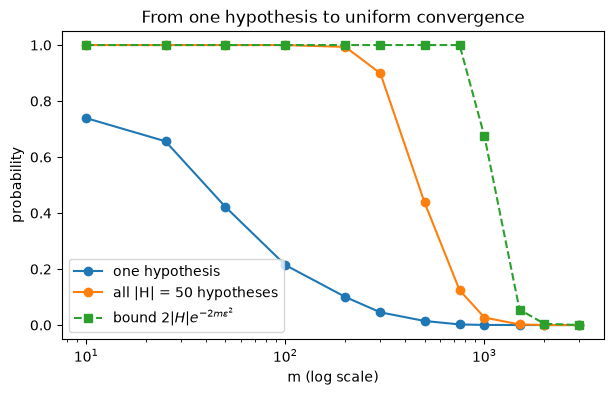

In [5]:
def make_class(K):
    """Finite class of K hypotheses: their true risks p_1, ..., p_K drawn uniformly in [0.05, 0.5]."""
    return rng.uniform(0.05, 0.5, size=K)


def max_deviation(m, p_class, n_rep=N_REP):
    """Simulate n_rep training samples and return Delta_S = max_h |L_S(h) - L_D(h)| for each one."""
    L_S = rng.binomial(m, p_class, size=(n_rep, len(p_class))) / m
    return np.abs(L_S - p_class).max(axis=1)


K = 50
p_class = make_class(K)
p_uniform = [np.mean(max_deviation(m, p_class) > EPSILON) for m in M_VALUES]
uc_bound = [min(1, 2 * K * np.exp(-2 * m * EPSILON**2)) for m in M_VALUES]

for m, prob, bound in zip(M_VALUES, p_uniform, uc_bound):
    print(f"m = {m:4d} | Pr(Delta_S > eps) = {prob:.4f} | bound 2|H|exp(-2m eps^2) = {bound:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(M_VALUES, p_single, "o-", label="one hypothesis")
plt.plot(M_VALUES, p_uniform, "o-", label=f"all |H| = {K} hypotheses")
plt.plot(M_VALUES, uc_bound, "s--", label="bound $2|H|e^{-2m\\varepsilon^2}$")
plt.xscale("log")
plt.xlabel("m (log scale)")
plt.ylabel("probability")
plt.title("From one hypothesis to uniform convergence")
plt.legend()
plt.show()

Controlling 50 hypotheses at once is much harder than controlling one: at m = 500, $\Pr[\Delta_S > \varepsilon] = 0.44$ against 0.015 for a single hypothesis, because it is enough that one of them deviates. The bound still holds but is even more conservative: it stays at 1 until m ≈ 1000 and gives 0.055 at m = 1500, where we measure 0.002.

## 4. Effect of the Size of the Hypothesis Class

Same experiment for |H| ∈ {5, 10, 50, 100, 500}. In the bound, |H| only appears through $\log |H|$:
$$2|H|e^{-2m\varepsilon^2} \le \delta \iff m \ge \frac{\log|H| + \log(2/\delta)}{2\varepsilon^2}.$$

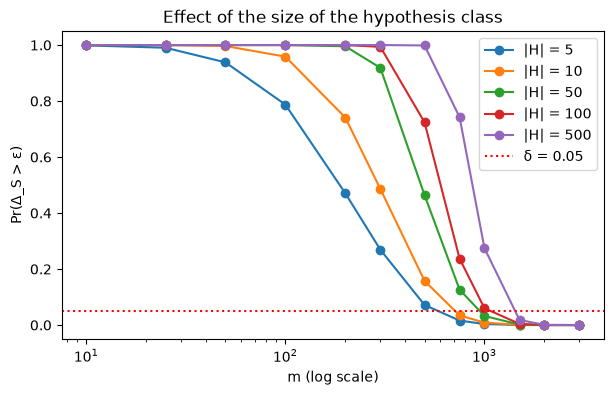

In [6]:
p_by_size = {}
for K in H_SIZES:
    p_class = make_class(K)
    p_by_size[K] = [np.mean(max_deviation(m, p_class) > EPSILON) for m in M_VALUES]

plt.figure(figsize=(7, 4))
for K in H_SIZES:
    plt.plot(M_VALUES, p_by_size[K], "o-", label=f"|H| = {K}")
plt.axhline(DELTA, color="red", linestyle=":", label="δ = 0.05")
plt.xscale("log")
plt.xlabel("m (log scale)")
plt.ylabel("Pr(Δ_S > ε)")
plt.title("Effect of the size of the hypothesis class")
plt.legend()
plt.show()

- **Effect of |H|**: the larger the class, the more hypotheses can deviate, so $\Pr[\Delta_S > \varepsilon]$ is higher for a given m and the curves move to the right.
- **More data?** Yes, a larger class needs more examples to get the same guarantee.
- **log |H|**: the shift is small. Multiplying |H| by 100 (from 5 to 500) only moves the curve by a factor of about 2 in m, not 100. This matches the $\log |H|$ term: in the theory, going from 5 to 500 adds $\log(100)/(2\varepsilon^2) \approx 920$ examples.

## 5. Experimental Sample Complexity

Smallest tested m with $\Pr[\Delta_S > \varepsilon] \le \delta$, compared with the sufficient size
$$m \ge \frac{\log(2|H|/\delta)}{2\varepsilon^2}.$$

In [7]:
print(f"{'|H|':>5} | {'experimental m':>14} | {'theoretical m':>13}")
for K in H_SIZES:
    m_exp = next(m for m, prob in zip(M_VALUES, p_by_size[K]) if prob <= DELTA)
    m_theory = np.log(2 * K / DELTA) / (2 * EPSILON**2)
    print(f"{K:>5} | {m_exp:>14} | {m_theory:>13.0f}")

  |H| | experimental m | theoretical m
    5 |            750 |          1060
   10 |            750 |          1198
   50 |           1000 |          1520
  100 |           1500 |          1659
  500 |           1500 |          1981


The experimental sample size is always smaller than the theoretical one (750 instead of 1060 for |H| = 5, 1500 instead of 1981 for |H| = 500), and both grow slowly with |H|. The theoretical value is a **sufficient** condition, not the minimum: Hoeffding is a worst-case inequality valid for every distribution, and the union bound adds the failure probabilities of all hypotheses as if their deviations never happened at the same time. Our grid of m is also coarse, so the real minimum can be even smaller.

# Part II – Simulating No-Free-Lunch

Domain $\mathcal{X} = \{1, \dots, N\}$ with the uniform distribution, and a new random target $f(x) \sim \text{Bernoulli}(1/2)$ for every task. The learner memorizes the labels it has seen and predicts 0 on unseen inputs.

## 6. Seen and Unseen Inputs

A fixed point x is missed by each of the m independent draws with probability $1 - 1/N$, so
$$\Pr[x \text{ is unseen}] = \left(1 - \frac{1}{N}\right)^m.$$

N = 100, m =   5 | unseen fraction = 0.9510 | (1 - 1/N)^m = 0.9510
N = 100, m =  10 | unseen fraction = 0.9044 | (1 - 1/N)^m = 0.9044
N = 100, m =  20 | unseen fraction = 0.8182 | (1 - 1/N)^m = 0.8179
N = 100, m =  50 | unseen fraction = 0.6056 | (1 - 1/N)^m = 0.6050
N = 100, m = 100 | unseen fraction = 0.3664 | (1 - 1/N)^m = 0.3660
N = 100, m = 200 | unseen fraction = 0.1339 | (1 - 1/N)^m = 0.1340
N = 100, m = 500 | unseen fraction = 0.0064 | (1 - 1/N)^m = 0.0066


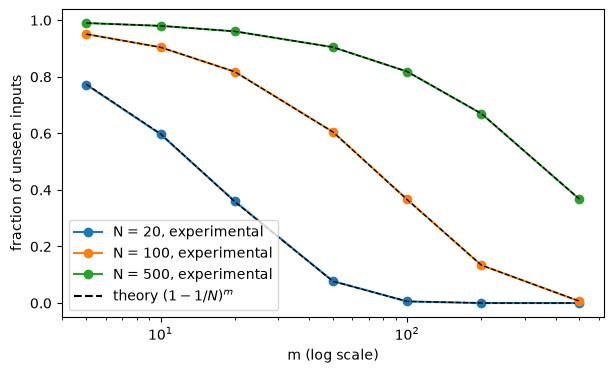

In [8]:
def run_task(N, m, unseen_rule="zero"):
    """One random task: return the fraction of unseen inputs and the true risk of the memorization learner."""
    f = rng.integers(0, 2, size=N)                 # random target, f(x) ~ Bernoulli(1/2)
    sample = rng.integers(0, N, size=m)            # S ~ D^m (uniform on the domain)
    seen = np.zeros(N, dtype=bool)
    seen[sample] = True

    if unseen_rule == "zero":
        guess = np.zeros(N, dtype=int)
    elif unseen_rule == "one":
        guess = np.ones(N, dtype=int)
    else:                                          # "random"
        guess = rng.integers(0, 2, size=N)

    prediction = np.where(seen, f, guess)          # observed label if seen, rule otherwise
    return 1 - seen.mean(), np.mean(prediction != f)


plt.figure(figsize=(7, 4))
for N in [20, 100, 500]:
    unseen = [np.mean([run_task(N, m)[0] for _ in range(N_REP_TASKS)]) for m in M_TASKS]
    plt.plot(M_TASKS, unseen, "o-", label=f"N = {N}, experimental")
    plt.plot(M_TASKS, [(1 - 1 / N) ** m for m in M_TASKS], "k--", linewidth=1)
    if N == N_DOMAIN:
        for m, u in zip(M_TASKS, unseen):
            print(f"N = {N}, m = {m:3d} | unseen fraction = {u:.4f} | (1 - 1/N)^m = {(1 - 1 / N) ** m:.4f}")
plt.plot([], [], "k--", label="theory $(1-1/N)^m$")
plt.xscale("log")
plt.xlabel("m (log scale)")
plt.ylabel("fraction of unseen inputs")
plt.legend()
plt.show()

The simulations match the formula for all N (dashed lines), e.g. 0.606 vs 0.605 for N = 100 and m = 50. It is also the expected **fraction** of unseen points because, by linearity of expectation,
$$\mathbb{E}\Big[\frac{1}{N}\sum_{x} \mathbb{1}[x \text{ unseen}]\Big] = \frac{1}{N}\sum_{x}\Pr[x \text{ unseen}] = \left(1-\frac{1}{N}\right)^m.$$
A larger domain needs many more examples to be covered: with m = N, about 37% of the points are still unseen.

## 7. Error on Unseen Inputs

The learner is always right on seen inputs, since it returns their true label. On an unseen input it predicts 0, and since $f(x) \sim \text{Bernoulli}(1/2)$ is independent of the sample, $\Pr[0 \neq f(x)] = 1/2$. By linearity of expectation:
$$\mathbb{E}[L_\mathcal{D}(A(S))] = \frac{1}{N}\sum_{x} \Pr[x \text{ unseen}] \cdot \frac{1}{2} = \frac{1}{2}\left(1 - \frac{1}{N}\right)^m.$$

m =   5 | E[L_D] experimental = 0.4744 | theory = 0.4755
m =  10 | E[L_D] experimental = 0.4531 | theory = 0.4522
m =  20 | E[L_D] experimental = 0.4098 | theory = 0.4090
m =  50 | E[L_D] experimental = 0.3009 | theory = 0.3025
m = 100 | E[L_D] experimental = 0.1826 | theory = 0.1830
m = 200 | E[L_D] experimental = 0.0661 | theory = 0.0670
m = 500 | E[L_D] experimental = 0.0031 | theory = 0.0033


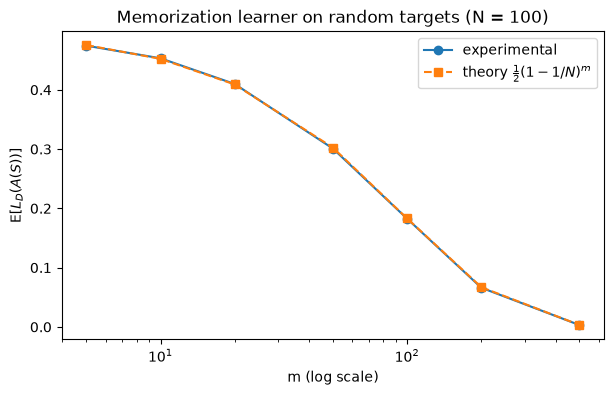

In [9]:
risk_random = [np.mean([run_task(N_DOMAIN, m)[1] for _ in range(N_REP_TASKS)]) for m in M_TASKS]
risk_theory = [0.5 * (1 - 1 / N_DOMAIN) ** m for m in M_TASKS]

for m, r, t in zip(M_TASKS, risk_random, risk_theory):
    print(f"m = {m:3d} | E[L_D] experimental = {r:.4f} | theory = {t:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(M_TASKS, risk_random, "o-", label="experimental")
plt.plot(M_TASKS, risk_theory, "s--", label="theory $\\frac{1}{2}(1-1/N)^m$")
plt.xscale("log")
plt.xlabel("m (log scale)")
plt.ylabel("E[$L_D(A(S))$]")
plt.title(f"Memorization learner on random targets (N = {N_DOMAIN})")
plt.legend()
plt.show()

Experiment and theory agree to within 0.002. The error only decreases because more inputs get **seen**, not because the learner understands anything about f: for m = 20 < N/2 the risk is still 0.41, far above the 1/8 of the No-Free-Lunch theorem, and it only becomes small when m is several times larger than N.

## 8. Changing the Prediction on Unseen Inputs

We compare three rules on unseen inputs: always 0, always 1, random Bernoulli(1/2). For any of them, an unseen label is a fair coin independent of the guess, so the expected risk is always $\frac{1}{2}(1 - 1/N)^m$.

In [10]:
print(f"{'m':>4} | {'predict 0':>9} | {'predict 1':>9} | {'random':>9}")
for m in M_TASKS:
    risks = [np.mean([run_task(N_DOMAIN, m, rule)[1] for _ in range(N_REP_TASKS)]) for rule in ["zero", "one", "random"]]
    print(f"{m:>4} | {risks[0]:>9.4f} | {risks[1]:>9.4f} | {risks[2]:>9.4f}")

   m | predict 0 | predict 1 |    random


   5 |    0.4736 |    0.4776 |    0.4737
  10 |    0.4506 |    0.4519 |    0.4520
  20 |    0.4078 |    0.4096 |    0.4069
  50 |    0.3018 |    0.3034 |    0.3028
 100 |    0.1824 |    0.1820 |    0.1825
 200 |    0.0667 |    0.0665 |    0.0661
 500 |    0.0034 |    0.0033 |    0.0034


The three rules give the same risk (the differences, at most 0.004, are Monte-Carlo noise), and none of them is consistently better. This is the No-Free-Lunch principle (Session 4): when all labelings are equally likely, the training sample says nothing about the unseen labels, so every way of filling them is right half of the time on average. A rule can only be better on some targets if it is worse on others.

# Part III – Introducing Prior Knowledge

The target is now a threshold $f_\theta(x) = \mathbb{1}[x > \theta]$ with $\theta \in \{1, \dots, N-1\}$, and the learner uses ERM over the same family
$$H = \{h_t(x) = \mathbb{1}[x > t] : t \in \{1, \dots, N-1\}\}.$$

## 9. Learning with a Matching Inductive Bias

For each task we draw θ, a sample, run ERM, and compute the true risk over the whole domain. $h_t$ and $f_\theta$ only disagree on the $|t - \theta|$ points between t and θ, so
$$L_\mathcal{D}(h_S) = \frac{|t_S - \theta|}{N}.$$

In [11]:
def erm_threshold(x_sample, y_sample, N):
    """ERM over h_t(x) = 1[x > t], t in {1, ..., N-1}: return the threshold with the smallest empirical error."""
    t_values = np.arange(1, N)
    errors = np.mean((x_sample[None, :] > t_values[:, None]) != y_sample[None, :], axis=1)
    return t_values[np.argmin(errors)]


def run_threshold_task(N, m):
    """One structured task: random threshold target, ERM, true risk over the whole domain."""
    theta = rng.integers(1, N)                   # theta in {1, ..., N-1}
    x_sample = rng.integers(1, N + 1, size=m)    # uniform on {1, ..., N}
    y_sample = (x_sample > theta).astype(int)
    t_hat = erm_threshold(x_sample, y_sample, N)
    return abs(t_hat - theta) / N                # h_t and f_theta disagree on |t - theta| points


risk_threshold = [np.mean([run_threshold_task(N_DOMAIN, m) for _ in range(N_REP_TASKS)]) for m in M_TASKS]

print(f"{'m':>4} | {'threshold target':>16} | {'random target':>13}")
for m, r_thr, r_rand in zip(M_TASKS, risk_threshold, risk_random):
    print(f"{m:>4} | {r_thr:>16.4f} | {r_rand:>13.4f}")

   m | threshold target | random target
   5 |           0.1370 |        0.4744
  10 |           0.0763 |        0.4531
  20 |           0.0409 |        0.4098
  50 |           0.0144 |        0.3009
 100 |           0.0055 |        0.1826
 200 |           0.0017 |        0.0661
 500 |           0.0000 |        0.0031


With the threshold assumption the risk is much smaller for the same data: 0.041 instead of 0.41 for m = 20, and 0.014 instead of 0.30 for m = 50. It also decreases much faster with m.

## 10. Random Targets vs. Structured Targets

Both learners receive exactly the same kind of sample. The only difference is the assumption on the target.

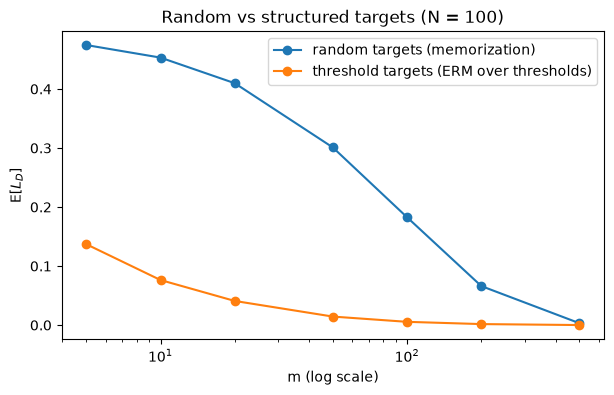

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(M_TASKS, risk_random, "o-", label="random targets (memorization)")
plt.plot(M_TASKS, risk_threshold, "o-", label="threshold targets (ERM over thresholds)")
plt.xscale("log")
plt.xlabel("m (log scale)")
plt.ylabel("E[$L_D$]")
plt.title(f"Random vs structured targets (N = {N_DOMAIN})")
plt.legend()
plt.show()

With random targets, an unseen input is a pure coin flip: nothing in the sample tells us its label, so the learner can only reduce its error by seeing more points. With thresholds, the labels are linked: once we see a 0 at x = 30 and a 1 at x = 45, every point below 30 must be 0 and every point above 45 must be 1. Only the few points between the last 0 and the first 1 remain uncertain, so the learner predicts correctly on most **unseen** inputs.

This works because we **assume** that the target belongs to the threshold family and we restrict H to the same family: this is the inductive bias (Sessions 1 and 4). It is the reason why generalization becomes possible.

## 11. Final Analysis

- **Concentration**: $L_S(h)$ is an average of m errors, so its standard deviation is $\sqrt{p(1-p)/m}$ and it concentrates around $L_\mathcal{D}(h)$ when m grows (Task 1), exponentially fast in probability as Hoeffding predicts (Task 2).
- **Uniform convergence**: ERM chooses the hypothesis with the smallest $L_S$, so we need $L_S \approx L_\mathcal{D}$ for **every** h at the same time, otherwise ERM could pick a hypothesis that only looks good by chance (Task 3).
- **Size of H**: more hypotheses means more chances that one of them deviates, so a larger class needs more data, but only through $\log |H|$ (Tasks 4 and 5).
- **Conservative bounds**: Hoeffding is a worst-case inequality and the union bound ignores that deviations overlap, so the theoretical sample size (≈ 1060 to 1980) is larger than what we measure (750 to 1500). It is a sufficient guarantee, not the exact minimum.
- **Random targets**: when every labeling is equally likely, the labels of unseen inputs are independent of the sample, so they cannot be predicted better than chance (Tasks 6 and 7).
- **No-Free-Lunch**: all rules for unseen inputs give the same risk (Task 8). A learner cannot infer arbitrary unseen labels from the training sample alone.
- **Prior knowledge**: restricting the target and the hypothesis class to thresholds adds an assumption that links the labels of different inputs.
- **Inductive bias**: thanks to this assumption, the observed examples tell us something about the unseen ones, and the risk becomes much smaller (0.014 instead of 0.30 for m = 50). Learning is possible only with such a bias, which is exactly the message of the No-Free-Lunch theorem.